# 2주차 환경 확인 노트북

> **이 노트북은 과제 제출 대상입니다.**
> 모든 셀을 위에서부터 실행한 뒤, **출력이 저장된 상태로** 저장(`Ctrl+S`)하고 커밋하세요.

**실행 전 확인** — 우측 상단 커널 이름이 **`Python (dl2026)`** 인지 보세요.
아니라면 클릭해서 바꾼 뒤 시작합니다.

---
## 셀 1. 나는 지금 어느 환경에서 실행 중인가

가장 중요한 줄은 **`실행 파일`** 입니다.
`%DL2026_HOME%\venv\Scripts\python.exe` 가 나와야 정상입니다.

In [1]:
# 파일: 01_env_check.ipynb (셀 1) — 나는 지금 어느 환경에서 실행 중인가
import os
import platform
import sys

print("실행 파일   :", sys.executable)
print("prefix      :", sys.prefix)
print("base_prefix :", sys.base_prefix)
print("가상환경 안?:", sys.prefix != sys.base_prefix)
print("파이썬 버전 :", platform.python_version())
print("VIRTUAL_ENV :", os.environ.get("VIRTUAL_ENV", "(설정 안 됨)"))

# → 실행 파일   : %DL2026_HOME%\venv\Scripts\python.exe
# → 가상환경 안?: True

실행 파일   : C:\Users\USER\Desktop\딥러닝\seoyeon2\venv\Scripts\python.exe
prefix      : C:\Users\USER\Desktop\딥러닝\seoyeon2\venv
base_prefix : C:\Program Files\Python313
가상환경 안?: True
파이썬 버전 : 3.13.3
VIRTUAL_ENV : C:\Users\USER\Desktop\딥러닝\seoyeon2\venv




---
## 셀 2. 커널이 바뀌면 무엇이 달라지는가 ★

`humanize` 는 우리 가상환경에만 설치한 **지문(fingerprint) 패키지**입니다.
시스템 파이썬에는 없습니다. 그래서 이 셀 하나로 커널이 제대로 잡혔는지 알 수 있습니다.

**실습 순서**
1. 지금 상태(`Python (dl2026)`)에서 실행 → 성공
2. 우측 상단 커널명을 클릭해 **`Python (다른환경)`** 으로 바꾸고 다시 실행 → 실패
3. 다시 `Python (dl2026)` 으로 되돌리고 실행 → 성공

> ⚠️ **`Python 3 (ipykernel)` 을 고르면 실패하지 않고 성공합니다.**
> 이름이 `Python 3` 라서 시스템 파이썬처럼 보이지만, 사실 **우리 venv 안에 들어 있는 커널**입니다
> (`venv\share\jupyter\kernels\python3`). `ipykernel` 을 설치할 때 딸려온 것이죠.
>
> **커널 이름만 보고 판단하면 안 됩니다 — `sys.executable` 을 봐야 압니다.**
> 이것이 오늘의 핵심입니다. 실습에는 2교시에 따로 만든 `Python (다른환경)` 을 쓰세요.

In [2]:
# 파일: 01_env_check.ipynb (셀 2) — 커널이 바뀌면 무엇이 달라지는가
import sys

print("실행 파일 :", sys.executable)

try:
    import humanize
    print("humanize OK  →", humanize.naturalsize(1234567))
except ModuleNotFoundError as e:
    print("humanize 없음 →", e)
    print("★ 지금 커널이 우리 가상환경이 아닙니다.")
    print("  우측 상단 커널명을 눌러 'Python (dl2026)' 을 선택하세요.")

# → 실행 파일 : %DL2026_HOME%\venv\Scripts\python.exe
# → humanize OK  → 1.2 MB

실행 파일 : C:\Users\USER\Desktop\딥러닝\seoyeon2\venv\Scripts\python.exe
humanize OK  → 1.2 MB


> **결과 해석**: "분명히 `pip install` 했는데 왜 없다고 하지?"
> 이것이 앞으로 학기 내내, 그리고 실무에서도 가장 자주 만나는 착각입니다.
> **패키지를 설치한 환경**과 **노트북이 실제로 실행 중인 환경**이 다른 것입니다.
> 답은 항상 `sys.executable` 한 줄로 나옵니다.

---
## 셀 3. 노트북 안에서 패키지를 설치할 때

`!pip` 는 셸을 새로 띄우기 때문에 **엉뚱한 환경에 설치될 수 있습니다.**
`%pip` 는 **지금 이 커널의 환경**에 설치합니다.

> **반드시 외우기 ★** — 노트북에서는 `!pip install` 이 아니라 **`%pip install`**

In [3]:
# 파일: 01_env_check.ipynb (셀 3) — 노트북 안에서 설치할 때
# 아래 줄의 맨 앞 # 을 지우고 실행해 보세요. 이미 설치되어 있으면 그렇다고 알려 줍니다.
# %pip install humanize

# 설치가 어디에 되는지 확인하는 방법
import sys
print("이 커널의 파이썬 :", sys.executable)
print("→ %pip 은 위 파이썬에 설치합니다.")

이 커널의 파이썬 : C:\Users\USER\Desktop\딥러닝\seoyeon2\venv\Scripts\python.exe
→ %pip 은 위 파이썬에 설치합니다.


---
## 셀 4. 설치한 패키지가 실제로 동작하는가

In [4]:
# 파일: 01_env_check.ipynb (셀 4) — numpy / pandas 동작 확인
import numpy as np
import pandas as pd

print("numpy  :", np.__version__)
print("pandas :", pd.__version__)

a = np.arange(12).reshape(3, 4)          # 3행 4열 배열
print("\n배열 shape :", a.shape)
print(a)

df = pd.DataFrame(a, columns=["c1", "c2", "c3", "c4"])
print("\n열별 평균")
print(df.mean())

numpy  : 2.5.2
pandas : 3.0.5

배열 shape : (3, 4)
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

열별 평균
c1    4.0
c2    5.0
c3    6.0
c4    7.0
dtype: float64


---
## 셀 5. matplotlib 그래프와 한글 폰트

Windows에서는 `Malgun Gothic`(맑은 고딕)을 쓰면 한글이 깨지지 않습니다.
`axes.unicode_minus = False` 는 음수 부호가 네모로 나오는 것을 막아 줍니다.

> 「데이터분석입문」 6주차에서 해 본 그 설정입니다. **코드만 확인하고 넘어갑니다.**

matplotlib : 3.11.1


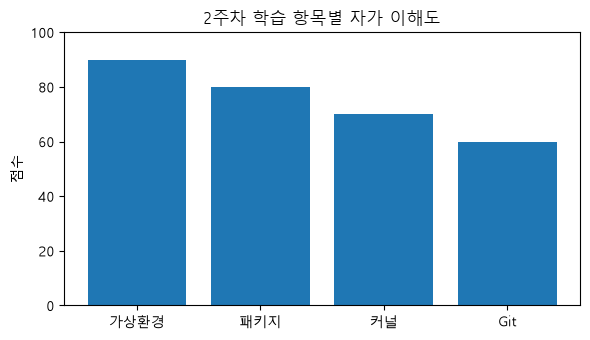

In [5]:
# 파일: 01_env_check.ipynb (셀 5) — 그래프와 한글 폰트
import matplotlib
import matplotlib.pyplot as plt

# Windows 한글 폰트 설정 (Mac은 "AppleGothic")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

print("matplotlib :", matplotlib.__version__)

과목 = ["가상환경", "패키지", "커널", "Git"]
이해도 = [90, 80, 70, 60]

plt.figure(figsize=(6, 3.5))
plt.bar(과목, 이해도)
plt.title("2주차 학습 항목별 자가 이해도")
plt.ylabel("점수")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

> **체험 팁**: 위 `이해도` 숫자를 **본인 실제 느낌으로 바꿔서** 다시 실행해 보세요.
> 이 노트북을 수정하는 것이 곧 3교시 "두 번째 커밋" 실습의 재료가 됩니다.

---
## 셀 6. 이 환경에 설치된 패키지 목록

In [6]:
# 파일: 01_env_check.ipynb (셀 6) — 설치된 패키지 확인
import subprocess
import sys

out = subprocess.run(
    [sys.executable, "-m", "pip", "list"],
    capture_output=True, text=True,
)
print(out.stdout)

Package                   Version
------------------------- -----------
anyio                     4.15.0
argon2-cffi               25.1.0
argon2-cffi-bindings      26.1.0
arrow                     1.4.0
asttokens                 3.0.2
async-lru                 2.3.0
attrs                     26.1.0
babel                     2.18.0
beautifulsoup4            4.15.0
bleach                    6.4.0
certifi                   2026.7.22
cffi                      2.1.1
charset-normalizer        3.5.1
colorama                  0.4.6
comm                      0.2.3
contourpy                 1.3.3
cycler                    0.12.1
debugpy                   1.8.21
defusedxml                0.7.1
executing                 2.2.1
fastjsonschema            2.22.2
fonttools                 4.64.0
fqdn                      1.5.1
h11                       0.16.0
httpcore                  1.0.9
httpx                     0.28.1
humanize                  4.16.0
idna                      3.19
ipykernel       

---
## 셀 7. 제출자 정보

**아래 세 줄을 본인 것으로 고친 뒤 실행하세요.** 이 출력이 저장된 상태로 커밋해야 합니다.

In [7]:
# 파일: 01_env_check.ipynb (셀 7) — 제출자 정보
from datetime import datetime

학번 = "20xxxxxx"          # ← 본인 학번
이름 = "홍길동"             # ← 본인 이름
깃허브 = "gildong-hong"     # ← 본인 GitHub ID

print("=" * 46)
print(f" 학번    : {학번}")
print(f" 이름    : {이름}")
print(f" GitHub  : {깃허브}")
print(f" 실행일시: {datetime.now():%Y-%m-%d %H:%M:%S}")
print("=" * 46)

 학번    : 20xxxxxx
 이름    : 홍길동
 GitHub  : gildong-hong
 실행일시: 2026-09-04 16:17:51


---
## 마지막 확인

```
[ ] 셀 1 의 '실행 파일' 이 %DL2026_HOME%\venv\Scripts\python.exe 이다
[ ] 셀 2 에서 humanize OK 가 나왔다
[ ] 셀 5 의 그래프에서 한글이 안 깨졌다
[ ] 셀 7 에 내 학번·이름·GitHub ID 가 들어 있다
[ ] Ctrl+S 로 저장했다 (출력이 함께 저장된다)
```

> **중요**: `Kernel > Restart & Clear Output` 을 누르면 **출력이 전부 지워집니다.**
> 커밋 직전에 누르지 마세요. 과제는 **출력이 남아 있는 상태**로 제출합니다.